In [71]:
import pandas as pd

import seaborn as sns

In [72]:
df = pd.read_csv("../data/ACLED.csv")

In [73]:
df.shape

(7056, 13)

In [74]:
df.dtypes

WEEK                       str
REGION                     str
COUNTRY                    str
ADMIN1                     str
EVENT_TYPE                 str
SUB_EVENT_TYPE             str
EVENTS                   int64
FATALITIES               int64
POPULATION_EXPOSURE        str
DISORDER_TYPE              str
ID                       int64
CENTROID_LATITUDE      float64
CENTROID_LONGITUDE     float64
dtype: object

In [75]:
df['WEEK'] = pd.to_datetime(df['WEEK'])

print(df['WEEK'].dtype)


datetime64[us]


In [76]:
df['EVENT_TYPE'].value_counts()

EVENT_TYPE
Battles                       2070
Violence against civilians    1861
Strategic developments        1283
Protests                      1040
Explosions/Remote violence     463
Riots                          339
Name: count, dtype: int64

In [77]:
df['SUB_EVENT_TYPE'].value_counts()

SUB_EVENT_TYPE
Armed clash                            1827
Attack                                 1452
Peaceful protest                        723
Arrests                                 316
Abduction/forced disappearance          287
Looting/property destruction            216
Violent demonstration                   206
Other                                   199
Agreement                               196
Change to group/activity                191
Excessive force against protesters      170
Protest with intervention               147
Non-state actor overtakes territory     145
Mob violence                            133
Shelling/artillery/missile attack       130
Air/drone strike                        128
Sexual violence                         122
Grenade                                 121
Disrupted weapons use                   106
Government regains territory             98
Remote explosive/landmine/IED            83
Non-violent transfer of territory        45
Headquarters or b

In [78]:
df['ADMIN1'].value_counts()

ADMIN1
Oromia                   2212
Amhara                   1685
Tigray                    680
Somali                    578
Addis Ababa               492
Benshangul/Gumuz          291
South Ethiopia Region     235
Afar                      232
Gambela                   218
Central Ethiopia          146
Dire Dawa                  87
Sidama                     84
South West                 63
Harari                     53
Name: count, dtype: int64

In [79]:
df['FATALITIES'].describe()

count    7056.000000
mean       12.301729
std       101.996209
min         0.000000
25%         0.000000
50%         0.000000
75%         7.000000
max      6461.000000
Name: FATALITIES, dtype: float64

mean of 12 with std 102 shows there are extreme outliners.
25% = 0, 25% of the data has fatalitiy of 0
50% = 0, 50% of the data has fatalitiy of 0
75% = 0, 75% of the data has fatalitity of 7 
- this implies large set of the data has lower fatalitiy with few extreme records 

In [80]:
df.nlargest(10,'FATALITIES')

,WEEK,REGION,COUNTRY,ADMIN1,EVENT_TYPE,SUB_EVENT_TYPE,EVENTS,FATALITIES,POPULATION_EXPOSURE,DISORDER_TYPE,ID,CENTROID_LATITUDE,CENTROID_LONGITUDE
6389,1999-03-13,Eastern Africa,Ethiopia,Tigray,Battles,Armed clash,7,6461,NaN,Political violence,909,13.5505,39.1466
6387,1999-02-06,Eastern Africa,Ethiopia,Tigray,Battles,Armed clash,4,3692,NaN,Political violence,909,13.5505,39.1466
494,1999-06-05,Eastern Africa,Ethiopia,Afar,Battles,Armed clash,2,1846,NaN,Political violence,897,11.6905,40.8789
6386,1999-01-30,Eastern Africa,Ethiopia,Tigray,Battles,Armed clash,2,1846,NaN,Political violence,909,13.5505,39.1466
3215,1999-07-17,Eastern Africa,Ethiopia,Oromia,Battles,Armed clash,4,1720,NaN,Political violence,903,6.9501,40.4140
6388,1999-02-13,Eastern Africa,Ethiopia,Tigray,Battles,Armed clash,1,923,NaN,Political violence,909,13.5505,39.1466
6941,1999-02-06,Eastern Africa,Ethiopia,Tigray,Violence against civilians,Attack,1,923,NaN,Political violence,909,13.5505,39.1466
6952,2020-11-07,Eastern Africa,Ethiopia,Tigray,Violence against civilians,Attack,6,730,91950,Political violence,909,13.5505,39.1466
2935,2002-06-15,Eastern Africa,Ethiopia,Gambela,Battles,Armed clash,6,699,NaN,Political violence,901,7.4946,34.5213
493,1998-06-06,Eastern Africa,Ethiopia,Afar,Battles,Armed clash,1,600,NaN,Political violence,897,11.6905,40.8789


In [81]:
df['WEEK'].unique()

<DatetimeArray>
['1997-10-04 00:00:00', '2001-11-24 00:00:00', '2002-04-06 00:00:00',
 '2011-03-19 00:00:00', '2011-09-10 00:00:00', '2012-06-02 00:00:00',
 '2013-03-02 00:00:00', '2017-08-19 00:00:00', '2017-09-30 00:00:00',
 '2017-11-18 00:00:00',
 ...
 '2009-04-25 00:00:00', '2009-12-26 00:00:00', '2015-06-27 00:00:00',
 '2015-07-04 00:00:00', '1999-03-27 00:00:00', '2013-01-26 00:00:00',
 '2001-11-03 00:00:00', '2013-10-05 00:00:00', '2010-06-05 00:00:00',
 '1998-07-11 00:00:00']
Length: 1158, dtype: datetime64[us]

In [82]:
df['WEEK'].min(), df['WEEK'].max()

(Timestamp('1997-01-11 00:00:00'), Timestamp('2026-09-05 00:00:00'))

In [83]:
df['EVENTS'].describe()

count    7056.000000
mean        2.739654
std         5.029280
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        98.000000
Name: EVENTS, dtype: float64

In [84]:
df['YEAR'] = df['WEEK'].dt.year

In [85]:
events_by_year = df.groupby('YEAR')['EVENTS'].sum()

In [86]:
events_by_year

YEAR
1997      23
1998      60
1999      73
2000     149
2001      52
2002     236
2003     112
2004     124
2005     129
2006      87
2007      46
2008     111
2009     102
2010     189
2011      85
2012     163
2013     136
2014     132
2015     386
2016    1218
2017     505
2018     876
2019     318
2020     716
2021    1905
2022    1608
2023    1789
2024    3018
2025    2884
2026    2099
Name: EVENTS, dtype: int64

In [87]:
fatalities_by_year = df.groupby('YEAR')['FATALITIES'].sum()

In [88]:
fatalities_by_year

YEAR
1997       84
1998      958
1999    18839
2000     1420
2001      894
2002     4192
2003      794
2004     1001
2005     1283
2006      366
2007     1423
2008      639
2009     1882
2010     1568
2011      655
2012      930
2013      539
2014      335
2015      813
2016     2591
2017     1281
2018     1584
2019      667
2020     4366
2021     8538
2022     6457
2023     3813
2024     7513
2025     6322
2026     5054
Name: FATALITIES, dtype: int64

In [89]:
df.groupby('YEAR')['EVENTS'].sum().tail(10)


YEAR
2017     505
2018     876
2019     318
2020     716
2021    1905
2022    1608
2023    1789
2024    3018
2025    2884
2026    2099
Name: EVENTS, dtype: int64

In [90]:
import matplotlib.pyplot as plt

<function matplotlib.pyplot.show(close=None, block=None)>

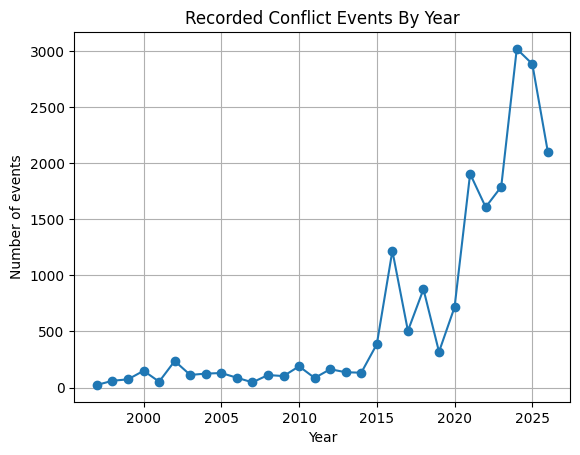

In [91]:
events_by_year.plot(kind = 'line', marker = 'o')

plt.title("Recorded Conflict Events By Year")

plt.xlabel('Year')

plt.ylabel('Number of events')

plt.grid(True)

plt.show

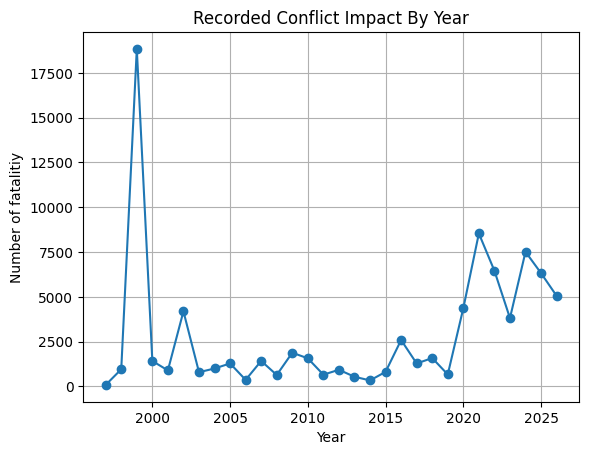

In [92]:
fatalities_by_year.plot(kind = 'line', marker = 'o')

plt.title("Recorded Conflict Impact By Year")

plt.xlabel('Year')

plt.ylabel('Number of fatalitiy')

plt.grid(True)

plt.show()

In [93]:
year_by_summary  = pd.DataFrame({
    'Events': events_by_year,
    'Fatalities': fatalities_by_year
})

In [94]:
year_by_summary

,Events,Fatalities
YEAR,,
1997,23,84
1998,60,958
1999,73,18839
2000,149,1420
2001,52,894
2002,236,4192
2003,112,794
2004,124,1001
2005,129,1283


In [95]:
year_by_summary['Fatalities_per_event'] = (
    year_by_summary['Fatalities'] / year_by_summary['Events']
)

year_by_summary

,Events,Fatalities,Fatalities_per_event
YEAR,,,
1997,23,84,3.652174
1998,60,958,15.966667
1999,73,18839,258.068493
2000,149,1420,9.530201
2001,52,894,17.192308
2002,236,4192,17.762712
2003,112,794,7.089286
2004,124,1001,8.072581
2005,129,1283,9.945736


Average value might not indicate values of fatality because extreme values can affect the reult

In [96]:
year_by_summary['Fatalities'].describe()

count       30.000000
mean      2893.366667
std       3808.942359
min         84.000000
25%        798.750000
50%       1351.500000
75%       4097.250000
max      18839.000000
Name: Fatalities, dtype: float64

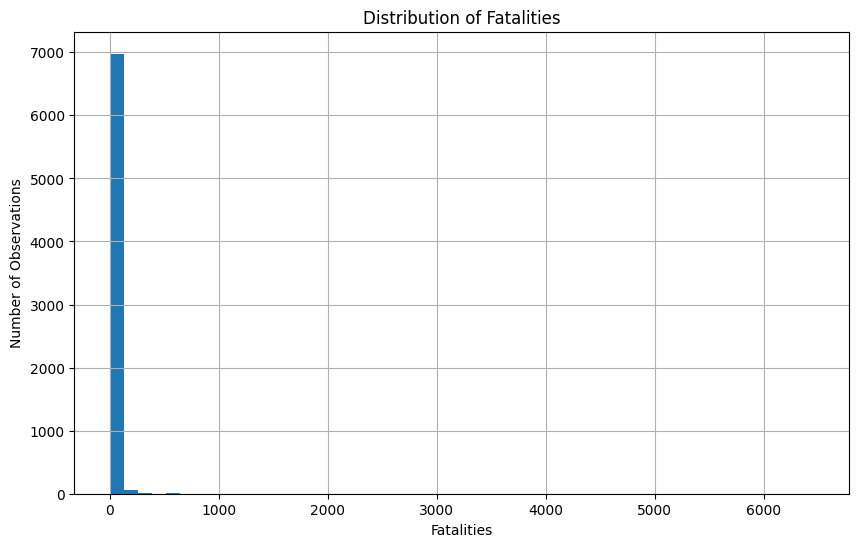

In [97]:
plt.figure(figsize=(10, 6))

plt.hist(df['FATALITIES'], bins=50)

plt.title("Distribution of Fatalities")
plt.xlabel("Fatalities")
plt.ylabel("Number of Observations")

plt.grid(True)
plt.show()

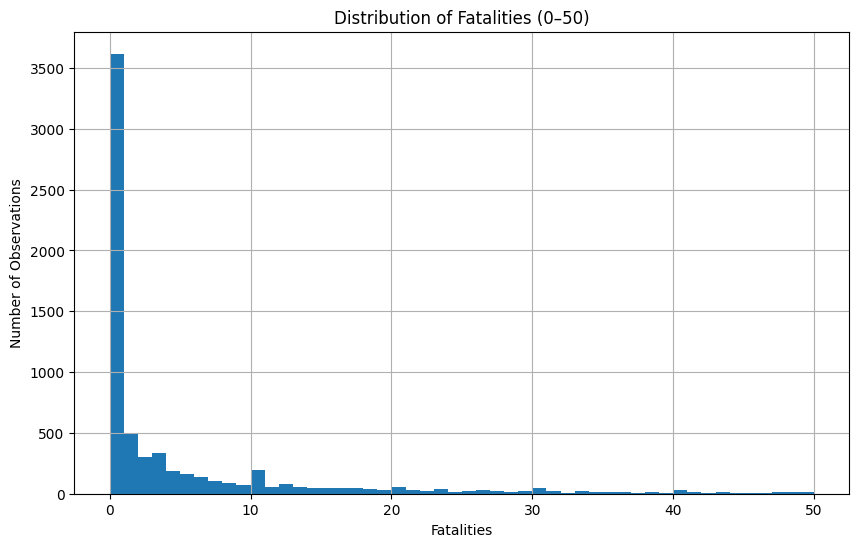

In [98]:
plt.figure(figsize=(10, 6))

plt.hist(df[df['FATALITIES'] <= 50]['FATALITIES'], bins=50)

plt.title("Distribution of Fatalities (0–50)")
plt.xlabel("Fatalities")
plt.ylabel("Number of Observations")

plt.grid(True)
plt.show()

In [99]:
df[df['FATALITIES'] <= 50]

,WEEK,REGION,COUNTRY,ADMIN1,EVENT_TYPE,SUB_EVENT_TYPE,EVENTS,FATALITIES,POPULATION_EXPOSURE,DISORDER_TYPE,ID,CENTROID_LATITUDE,CENTROID_LONGITUDE,YEAR
0,1997-10-04,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,3,Column 1,Political violence,896,8.9644,38.7756,1997
1,2001-11-24,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,1,NaN,Political violence,896,8.9644,38.7756,2001
3,2011-03-19,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,0,NaN,Political violence,896,8.9644,38.7756,2011
4,2011-09-10,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,4,NaN,Political violence,896,8.9644,38.7756,2011
5,2012-06-02,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,2,NaN,Political violence,896,8.9644,38.7756,2012
6,2013-03-02,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,0,NaN,Political violence,896,8.9644,38.7756,2013
7,2017-08-19,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,0,1109988,Political violence,896,8.9644,38.7756,2017
8,2017-09-30,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,3,1109988,Political violence,896,8.9644,38.7756,2017
9,2017-11-18,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,10,1120456,Political violence,896,8.9644,38.7756,2017
10,2018-09-15,Eastern Africa,Ethiopia,Addis Ababa,Battles,Armed clash,1,1,378220,Political violence,896,8.9644,38.7756,2018


In [100]:
df[df['FATALITIES'] > 50]['FATALITIES'].describe()

count     343.000000
mean      158.527697
std       436.331991
min        51.000000
25%        62.000000
50%        80.000000
75%       123.000000
max      6461.000000
Name: FATALITIES, dtype: float64

In [101]:
df['ADMIN1'].value_counts()

ADMIN1
Oromia                   2212
Amhara                   1685
Tigray                    680
Somali                    578
Addis Ababa               492
Benshangul/Gumuz          291
South Ethiopia Region     235
Afar                      232
Gambela                   218
Central Ethiopia          146
Dire Dawa                  87
Sidama                     84
South West                 63
Harari                     53
Name: count, dtype: int64

In [102]:
events_by_region = df.groupby("ADMIN1")['EVENTS'].sum()

events_by_region = events_by_region.sort_values(ascending=False)

events_by_region

ADMIN1
Oromia                   7218
Amhara                   6518
Tigray                   1941
Somali                   1060
Addis Ababa               590
Afar                      433
Benshangul/Gumuz          382
South Ethiopia Region     344
Gambela                   312
Central Ethiopia          190
Sidama                    111
Dire Dawa                 106
South West                 71
Harari                     55
Name: EVENTS, dtype: int64

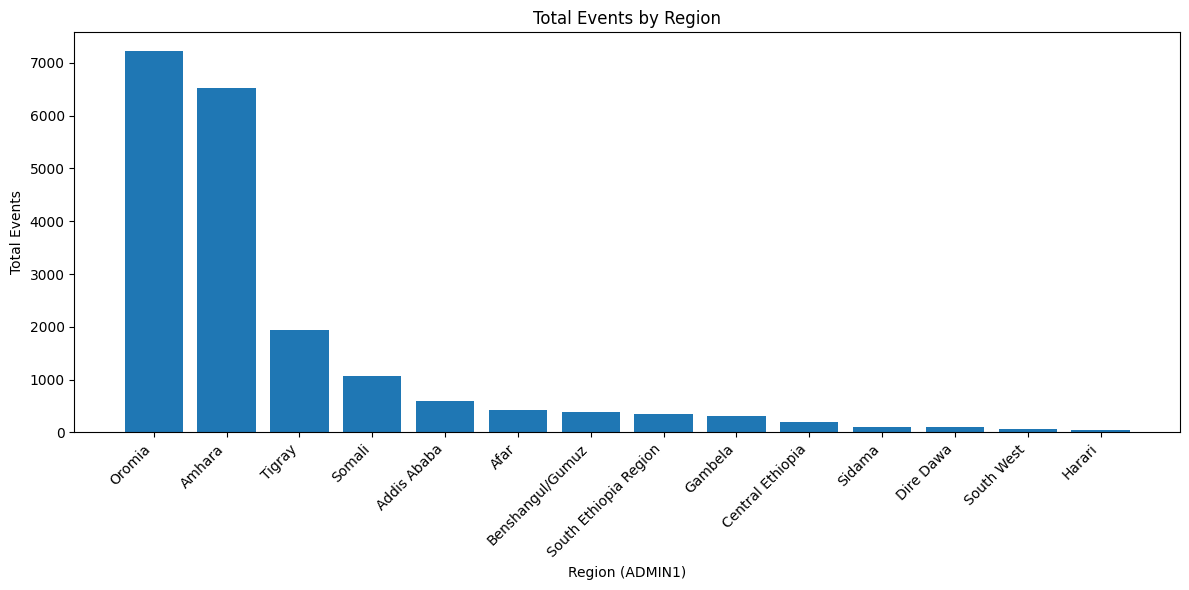

In [103]:
plt.figure(figsize=(12, 6))
plt.bar(events_by_region.index, events_by_region.values)
plt.xlabel("Region (ADMIN1)")
plt.ylabel("Total Events")
plt.title("Total Events by Region")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [104]:
fatality_by_region = df.groupby('ADMIN1')['FATALITIES'].sum()

fatality_by_region = fatality_by_region.sort_values(ascending=False)

fatality_by_region


ADMIN1
Oromia                   22888
Amhara                   20130
Tigray                   20010
Somali                    9801
Afar                      4620
Benshangul/Gumuz          2928
Gambela                   2892
South Ethiopia Region      999
Sidama                     656
Addis Ababa                547
Central Ethiopia           513
South West                 467
Dire Dawa                  195
Harari                     155
Name: FATALITIES, dtype: int64

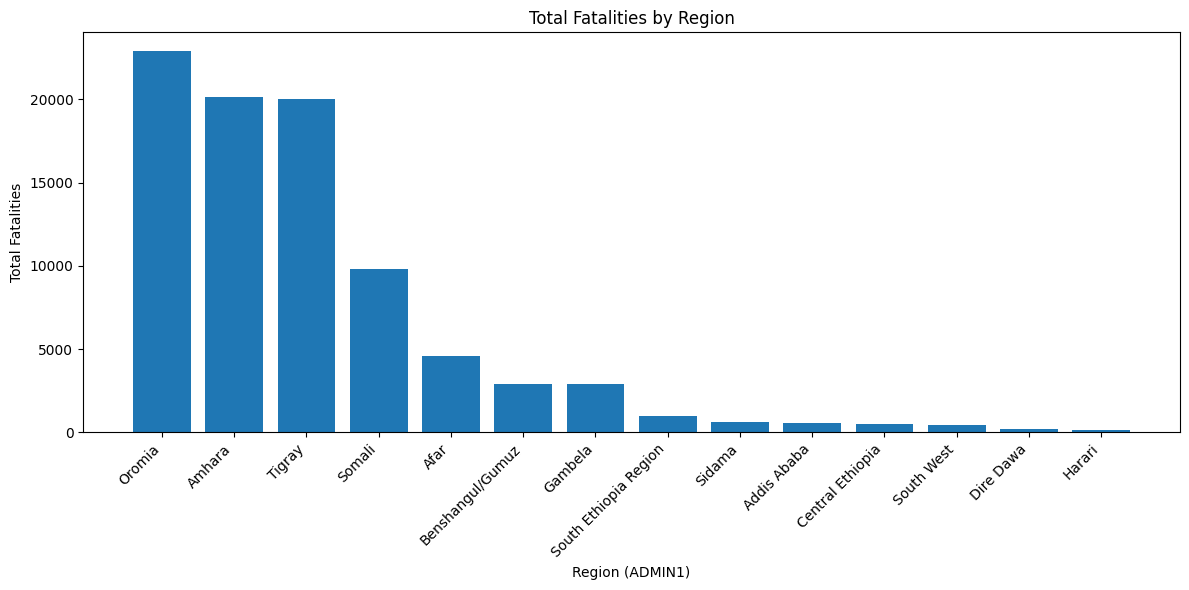

In [105]:
plt.figure(figsize=(12, 6))
plt.bar(fatality_by_region.index, fatality_by_region.values)
plt.xlabel("Region (ADMIN1)")
plt.ylabel("Total Fatalities")
plt.title("Total Fatalities by Region")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [106]:
print(df.dtypes)

WEEK                   datetime64[us]
REGION                            str
COUNTRY                           str
ADMIN1                            str
EVENT_TYPE                        str
SUB_EVENT_TYPE                    str
EVENTS                          int64
FATALITIES                      int64
POPULATION_EXPOSURE               str
DISORDER_TYPE                     str
ID                              int64
CENTROID_LATITUDE             float64
CENTROID_LONGITUDE            float64
YEAR                            int32
dtype: object


In [107]:
df.isnull().sum()

WEEK                      0
REGION                    0
COUNTRY                   0
ADMIN1                    0
EVENT_TYPE                0
SUB_EVENT_TYPE            0
EVENTS                    0
FATALITIES                0
POPULATION_EXPOSURE    2436
DISORDER_TYPE             0
ID                        0
CENTROID_LATITUDE         0
CENTROID_LONGITUDE        0
YEAR                      0
dtype: int64

In [108]:
fatalities_by_region = (
    df.groupby('ADMIN1')['FATALITIES'].sum().sort_values(ascending=False)
)

region_summary = pd.DataFrame({
    'Events': events_by_region,
    'Fatalities': fatalities_by_region
})

region_summary['Fatalities_per_event'] = (
    region_summary['Fatalities'] / region_summary['Events']
)

region_summary

,Events,Fatalities,Fatalities_per_event
ADMIN1,,,
Addis Ababa,590,547,0.927119
Afar,433,4620,10.669746
Amhara,6518,20130,3.088371
Benshangul/Gumuz,382,2928,7.664921
Central Ethiopia,190,513,2.700000
Dire Dawa,106,195,1.839623
Gambela,312,2892,9.269231
Harari,55,155,2.818182
Oromia,7218,22888,3.170961


In [109]:
events_by_type = (
    df.groupby('EVENT_TYPE')['EVENTS'].sum().sort_values(ascending=False)
)

events_by_type

# number of events for each event type 

EVENT_TYPE
Battles                       9344
Violence against civilians    4012
Protests                      2939
Strategic developments        1767
Explosions/Remote violence     697
Riots                          572
Name: EVENTS, dtype: int64

In [110]:
fatalities_by_type = (
    df.groupby('EVENT_TYPE')['FATALITIES'].sum().sort_values(ascending=False)
)

fatalities_by_type

# number of fatality caused by each event type

EVENT_TYPE
Battles                       63983
Violence against civilians    17325
Explosions/Remote violence     3210
Riots                          1149
Protests                       1104
Strategic developments           30
Name: FATALITIES, dtype: int64

In [111]:
type_summary = pd.DataFrame({
    'Events': events_by_type,
    'Fatalities': fatalities_by_type
})

type_summary['Fatalities_per_event'] = (
    type_summary['Fatalities'] / type_summary['Events']
)

type_summary

,Events,Fatalities,Fatalities_per_event
EVENT_TYPE,,,
Battles,9344,63983,6.847496
Explosions/Remote violence,697,3210,4.605452
Protests,2939,1104,0.375638
Riots,572,1149,2.008741
Strategic developments,1767,30,0.016978
Violence against civilians,4012,17325,4.318295


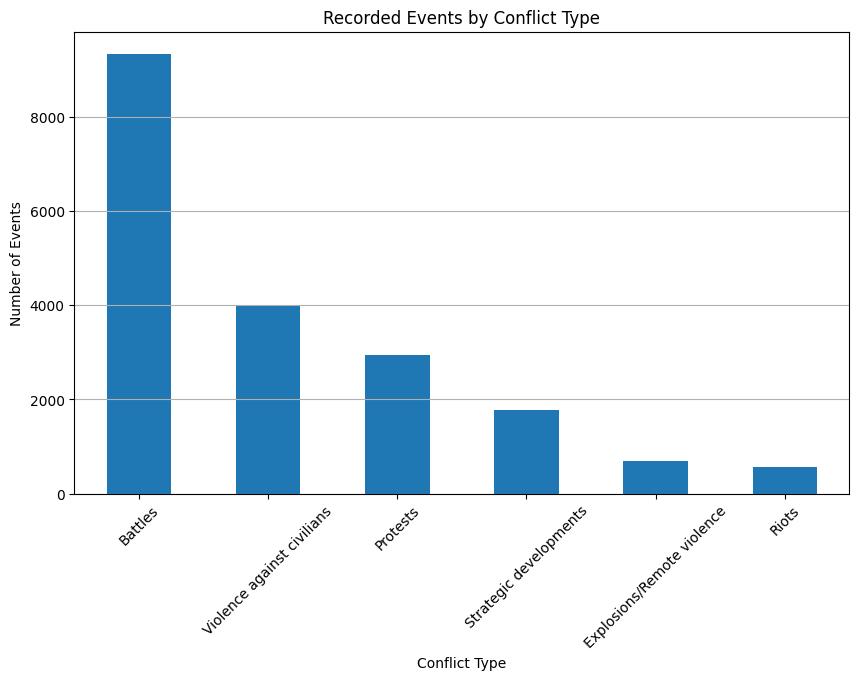

In [112]:
events_by_type.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Recorded Events by Conflict Type")
plt.xlabel("Conflict Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

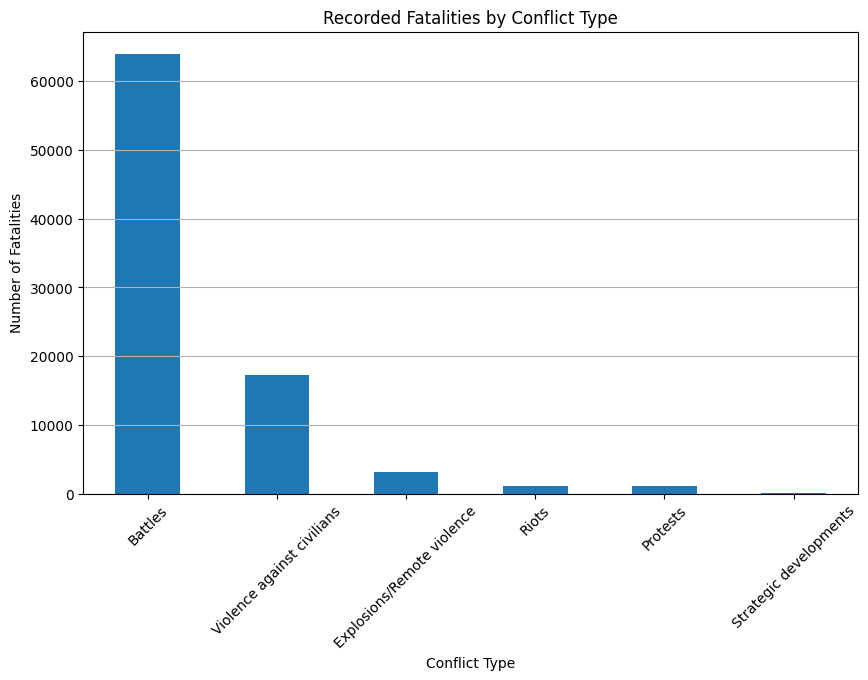

In [113]:
fatalities_by_type.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Recorded Fatalities by Conflict Type")
plt.xlabel("Conflict Type")
plt.ylabel("Number of Fatalities")
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

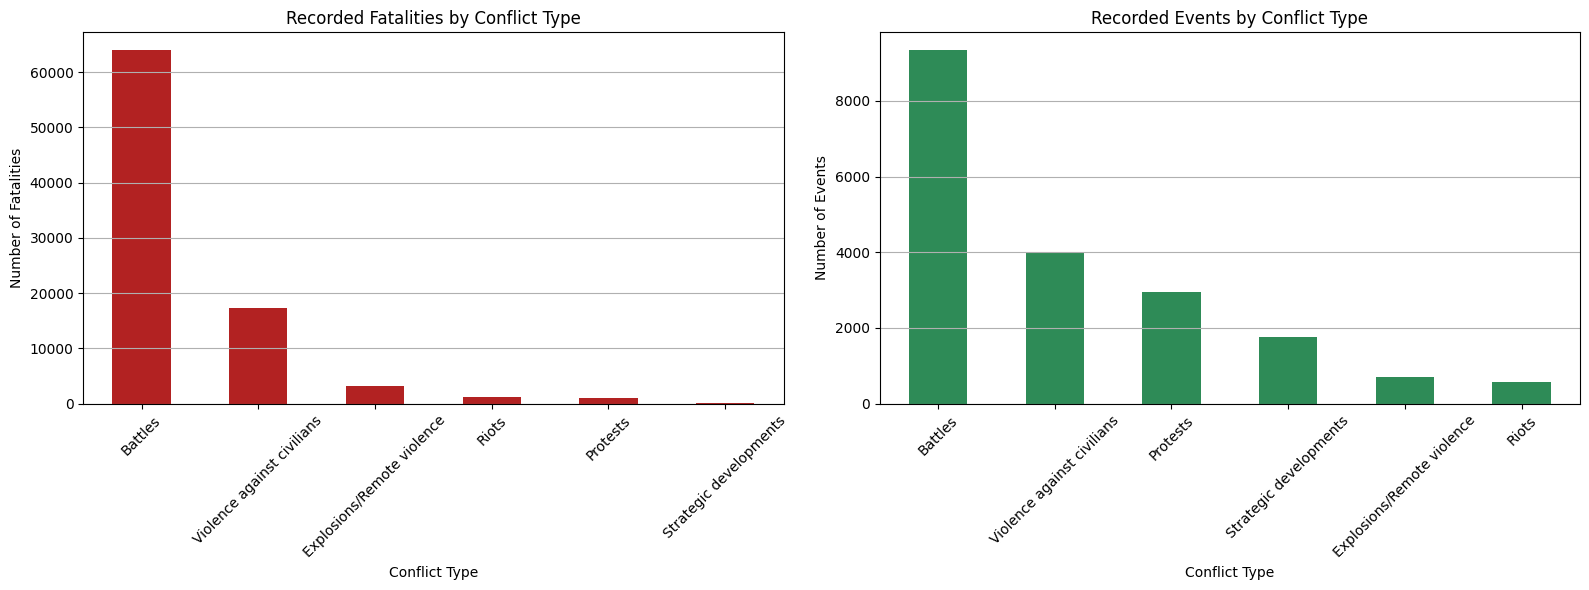

In [114]:


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Fatalities by Conflict Type
fatalities_by_type.plot(kind='bar', ax=axes[0], color='firebrick')
axes[0].set_title("Recorded Fatalities by Conflict Type")
axes[0].set_xlabel("Conflict Type")
axes[0].set_ylabel("Number of Fatalities")
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y')

# Right: Events by Conflict Type
events_by_type.plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title("Recorded Events by Conflict Type")
axes[1].set_xlabel("Conflict Type")
axes[1].set_ylabel("Number of Events")
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()

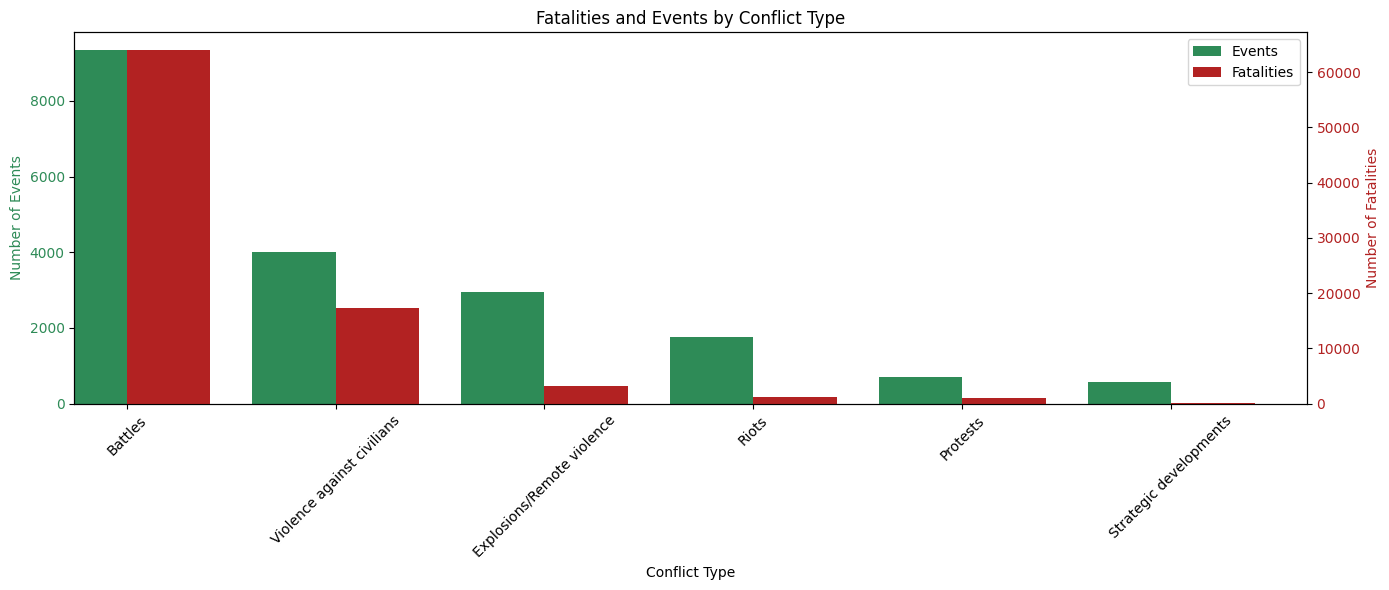

In [115]:

fig, ax1 = plt.subplots(figsize=(14, 6))

# Primary axis — Events
events_by_type.plot(kind='bar', ax=ax1, color='seagreen', position=1,
                    width=0.4, label='Events')
ax1.set_ylabel("Number of Events", color='seagreen')
ax1.tick_params(axis='y', labelcolor='seagreen')

# Secondary axis — Fatalities
ax2 = ax1.twinx()
fatalities_by_type.plot(kind='bar', ax=ax2, color='firebrick', position=0,
                        width=0.4, label='Fatalities')
ax2.set_ylabel("Number of Fatalities", color='firebrick')
ax2.tick_params(axis='y', labelcolor='firebrick')

ax1.set_xlabel("Conflict Type")
ax1.set_title("Fatalities and Events by Conflict Type")
ax1.tick_params(axis='x', rotation=45)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

In [116]:
events_by_subtype = (
    df.groupby('SUB_EVENT_TYPE')['EVENTS']
    .sum()
    .sort_values(ascending=False)
)

events_by_subtype

SUB_EVENT_TYPE
Armed clash                            8816
Attack                                 3400
Peaceful protest                       2189
Excessive force against protesters      509
Abduction/forced disappearance          418
Violent demonstration                   391
Arrests                                 390
Agreement                               325
Non-state actor overtakes territory     321
Looting/property destruction            304
Air/drone strike                        256
Change to group/activity                254
Other                                   253
Protest with intervention               241
Government regains territory            207
Shelling/artillery/missile attack       204
Sexual violence                         194
Mob violence                            181
Grenade                                 143
Disrupted weapons use                   127
Non-violent transfer of territory        97
Remote explosive/landmine/IED            93
Headquarters or b

In [117]:
pd.set_option('display.max_rows', None)


events_region_subtype = (
    df.groupby(['ADMIN1', 'EVENT_TYPE'])['EVENTS']
    .sum()
)

# grouped by two fields

events_region_subtype

ADMIN1                 EVENT_TYPE                
Addis Ababa            Battles                         19
                       Explosions/Remote violence      24
                       Protests                       198
                       Riots                           68
                       Strategic developments         197
                       Violence against civilians      84
Afar                   Battles                        253
                       Explosions/Remote violence      30
                       Protests                        58
                       Riots                            6
                       Strategic developments          26
                       Violence against civilians      60
Amhara                 Battles                       4306
                       Explosions/Remote violence     344
                       Protests                       382
                       Riots                           83
                      

In [118]:
events_region_event_type_table = (
    df.pivot_table(
        index='ADMIN1',
        columns='EVENT_TYPE',
        values='EVENTS',
        aggfunc='sum',
        fill_value=0
    )
)

events_region_event_type_table

EVENT_TYPE,Battles,Explosions/Remote violence,Protests,Riots,Strategic developments,Violence against civilians
ADMIN1,,,,,,
Addis Ababa,19,24,198,68,197,84
Afar,253,30,58,6,26,60
Amhara,4306,344,382,83,578,825
Benshangul/Gumuz,129,5,17,4,75,152
Central Ethiopia,35,3,48,24,23,57
Dire Dawa,14,6,39,23,5,19
Gambela,106,7,11,14,31,143
Harari,17,3,14,9,3,9
Oromia,2667,118,1644,261,502,2026


groupby

pivot table 

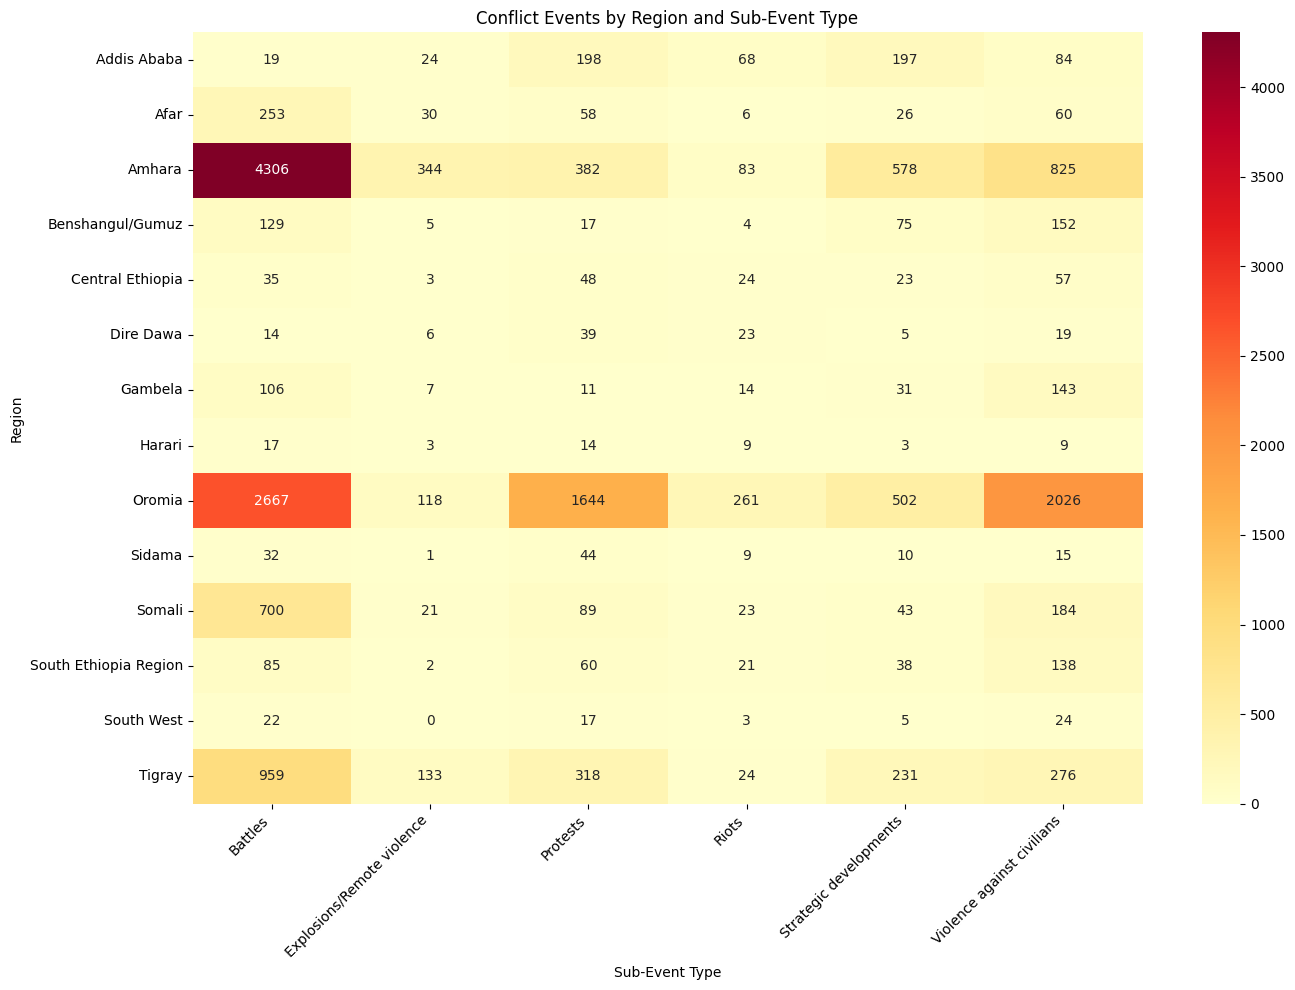

In [119]:
plt.figure(figsize=(14,10))

sns.heatmap(events_region_event_type_table,
            annot = True,
            fmt='g',
            cmap='YlOrRd'
            )
plt.title('Conflict Events by Region and Sub-Event Type')
plt.xlabel("Sub-Event Type")
plt.ylabel("Region")

plt.xticks(rotation=45, ha ='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [120]:
events_year_type = (
        df.groupby(['YEAR','EVENT_TYPE','ADMIN1'])['FATALITIES'].sum()
)
   
events_year_type

YEAR  EVENT_TYPE                  ADMIN1               
1997  Battles                     Addis Ababa                  3
                                  Oromia                      26
                                  Sidama                      24
      Explosions/Remote violence  Addis Ababa                  2
                                  Dire Dawa                    0
                                  Harari                       2
      Protests                    Addis Ababa                  0
      Strategic developments      Gambela                      0
      Violence against civilians  Addis Ababa                  4
                                  Oromia                      16
                                  Sidama                       3
                                  Somali                       4
                                  South Ethiopia Region        0
1998  Battles                     Afar                       600
                                  

In [121]:
battles = (
    df[df['EVENT_TYPE'] == 'Battles']
    .groupby(['YEAR', 'ADMIN1'])['FATALITIES']
    .sum()
    .reset_index()
)

battles

,YEAR,ADMIN1,FATALITIES
0,1997,Addis Ababa,3
1,1997,Oromia,26
2,1997,Sidama,24
3,1998,Afar,600
4,1998,Oromia,0
5,1998,Somali,87
6,1998,South Ethiopia Region,140
7,1998,Tigray,0
8,1999,Afar,1846
9,1999,Central Ethiopia,202


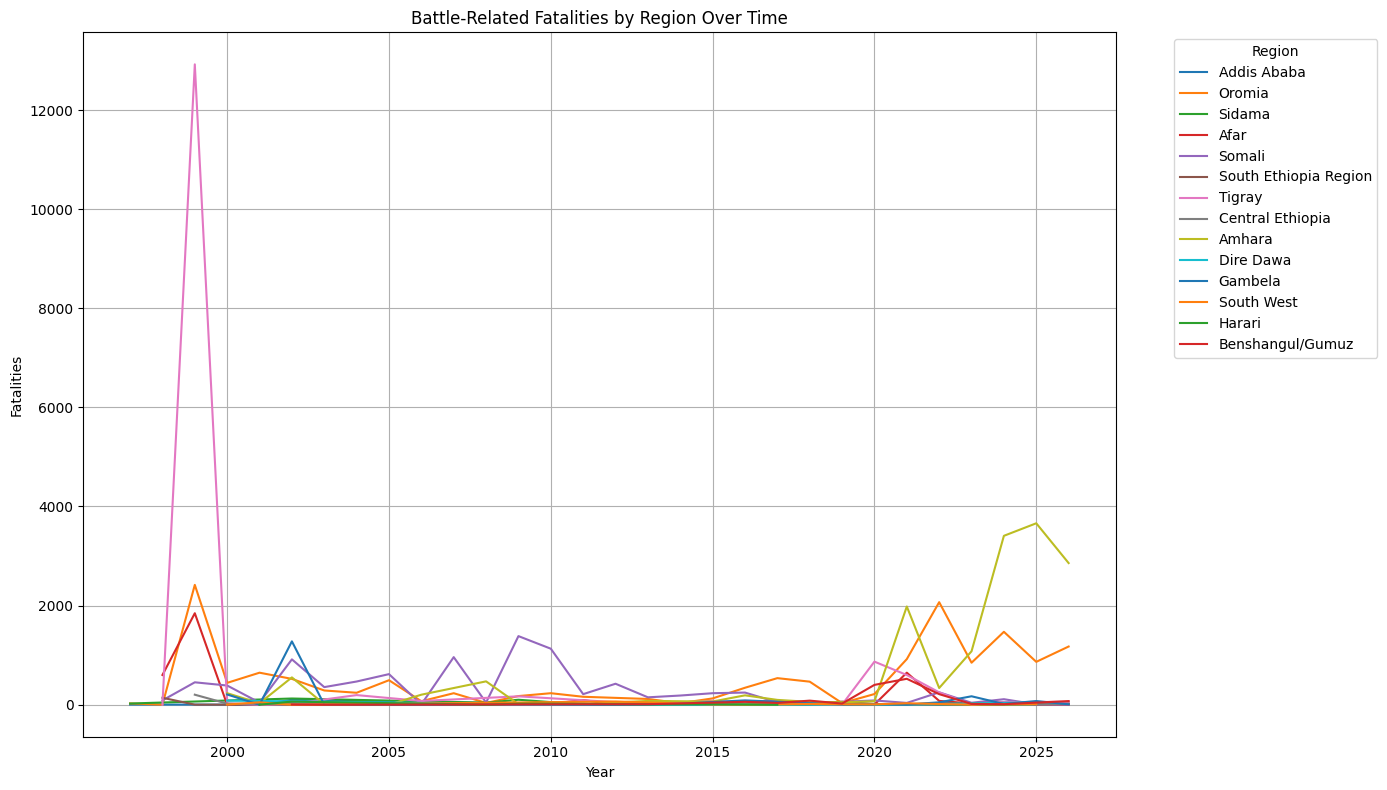

In [122]:
plt.figure(figsize=(14, 8))

for region in battles['ADMIN1'].unique():
    region_data = battles[battles['ADMIN1'] == region]
    
    plt.plot(
        region_data['YEAR'],
        region_data['FATALITIES'],
        label=region
    )

plt.title("Battle-Related Fatalities by Region Over Time")
plt.xlabel("Year")
plt.ylabel("Fatalities")

plt.legend(
    title="Region",
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [123]:
region_year_fatalities = (
    df.groupby(['YEAR','ADMIN1'])['FATALITIES']
    .sum()
    .reset_index()
    )

region_year_fatalities.head()

,YEAR,ADMIN1,FATALITIES
0,1997,Addis Ababa,9
1,1997,Dire Dawa,0
2,1997,Gambela,0
3,1997,Harari,2
4,1997,Oromia,42


In [124]:
top_region_each_year = (region_year_fatalities.
                        loc[
    region_year_fatalities.groupby('YEAR')['FATALITIES'].idxmax()
].sort_values('YEAR'))

top_region_each_year

,YEAR,ADMIN1,FATALITIES
4,1997,Oromia,42
9,1998,Afar,600
25,1999,Tigray,13861
32,2000,Oromia,447
41,2001,Oromia,671
51,2002,Gambela,1419
64,2003,Somali,362
71,2004,Somali,479
82,2005,Somali,669
86,2006,Amhara,203


In [125]:
# year_by_summary['Fatalities_per_event'] = (year_by_summary['Fatalities'] / yearly_summary['Events'])

yearly_intensity = (year_by_summary
                    .sort_values('Fatalities_per_event', ascending=False))

yearly_intensity

,Events,Fatalities,Fatalities_per_event
YEAR,,,
1999,73,18839,258.068493
2007,46,1423,30.934783
2009,102,1882,18.450980
2002,236,4192,17.762712
2001,52,894,17.192308
1998,60,958,15.966667
2005,129,1283,9.945736
2000,149,1420,9.530201
2010,189,1568,8.296296


In [126]:
year_by_summary[['Events', 'Fatalities']].mean()

Events         644.366667
Fatalities    2893.366667
dtype: float64

In [127]:
year_by_summary['Fatalities_z'] = (
    (year_by_summary['Fatalities'] - year_by_summary['Fatalities'].mean())
    / year_by_summary['Fatalities'].std()
)

year_by_summary[['Fatalities','Fatalities_z']]

# Z score to find anomalies

,Fatalities,Fatalities_z
YEAR,,
1997,84,-0.737571
1998,958,-0.508111
1999,18839,4.186368
2000,1420,-0.386818
2001,894,-0.524914
2002,4192,0.340943
2003,794,-0.551168
2004,1001,-0.496822
2005,1283,-0.422786


In [128]:
high_fatality_years = year_by_summary[year_by_summary['Fatalities_z'] > 2]

high_fatality_years

,Events,Fatalities,Fatalities_per_event,Fatalities_z
YEAR,,,,
1999,73,18839,258.068493,4.186368


In [129]:
anomaly_year = 1999

regional_anomaly = (
    df[df['YEAR'] == anomaly_year]
    .groupby(['ADMIN1', 'EVENT_TYPE'])['FATALITIES']
    .sum()
    .sort_values(ascending=False)
)

regional_anomaly

ADMIN1                 EVENT_TYPE                
Tigray                 Battles                       12922
Oromia                 Battles                        2418
Afar                   Battles                        1846
Tigray                 Violence against civilians      923
Somali                 Battles                         452
Central Ethiopia       Battles                         202
Amhara                 Violence against civilians       25
Tigray                 Explosions/Remote violence       16
Somali                 Violence against civilians       15
South Ethiopia Region  Violence against civilians        7
Oromia                 Violence against civilians        5
Afar                   Explosions/Remote violence        3
                       Violence against civilians        2
Dire Dawa              Explosions/Remote violence        2
South Ethiopia Region  Battles                           1
Name: FATALITIES, dtype: int64

- battles ranked as the top three contributors in 1999, in Tigray, Oromia and Afar respectively.

In [130]:
id ="v7q31m"
event_type_1999 = (
    df[df['YEAR'] == 1999]
    .groupby('EVENT_TYPE')['FATALITIES']
    .sum()
    .sort_values(ascending=False)

)

event_type_1999





EVENT_TYPE
Battles                       17841
Violence against civilians      977
Explosions/Remote violence       21
Name: FATALITIES, dtype: int64

In [131]:
id="b4k8zx"
event_type_1999_percentage = (
     event_type_1999 /event_type_1999.sum() * 100
)

event_type_1999_percentage

EVENT_TYPE
Battles                       94.702479
Violence against civilians     5.186050
Explosions/Remote violence     0.111471
Name: FATALITIES, dtype: float64

weekly-conflict

In [132]:
from IPython.display import HTML, display

region_weekly_summary = (
    df.groupby(['WEEK','ADMIN1'])
    .agg({
        'EVENTS': 'sum',
        'FATALITIES': 'sum'
    })
    .reset_index()
)

display(HTML(
    '<div style="max-height: 200px; overflow: auto;">'
    + region_weekly_summary.to_html(index=False)
    + '</div>'
))

WEEK,ADMIN1,EVENTS,FATALITIES
1997-01-11,Gambela,1,0
1997-02-08,Harari,1,2
1997-02-15,Gambela,1,0
1997-03-15,Addis Ababa,1,0
1997-03-29,Addis Ababa,1,0
1997-04-12,Addis Ababa,3,1
1997-04-26,Dire Dawa,1,0
1997-05-03,Addis Ababa,1,1
1997-05-10,South Ethiopia Region,1,0
1997-06-07,Oromia,2,16


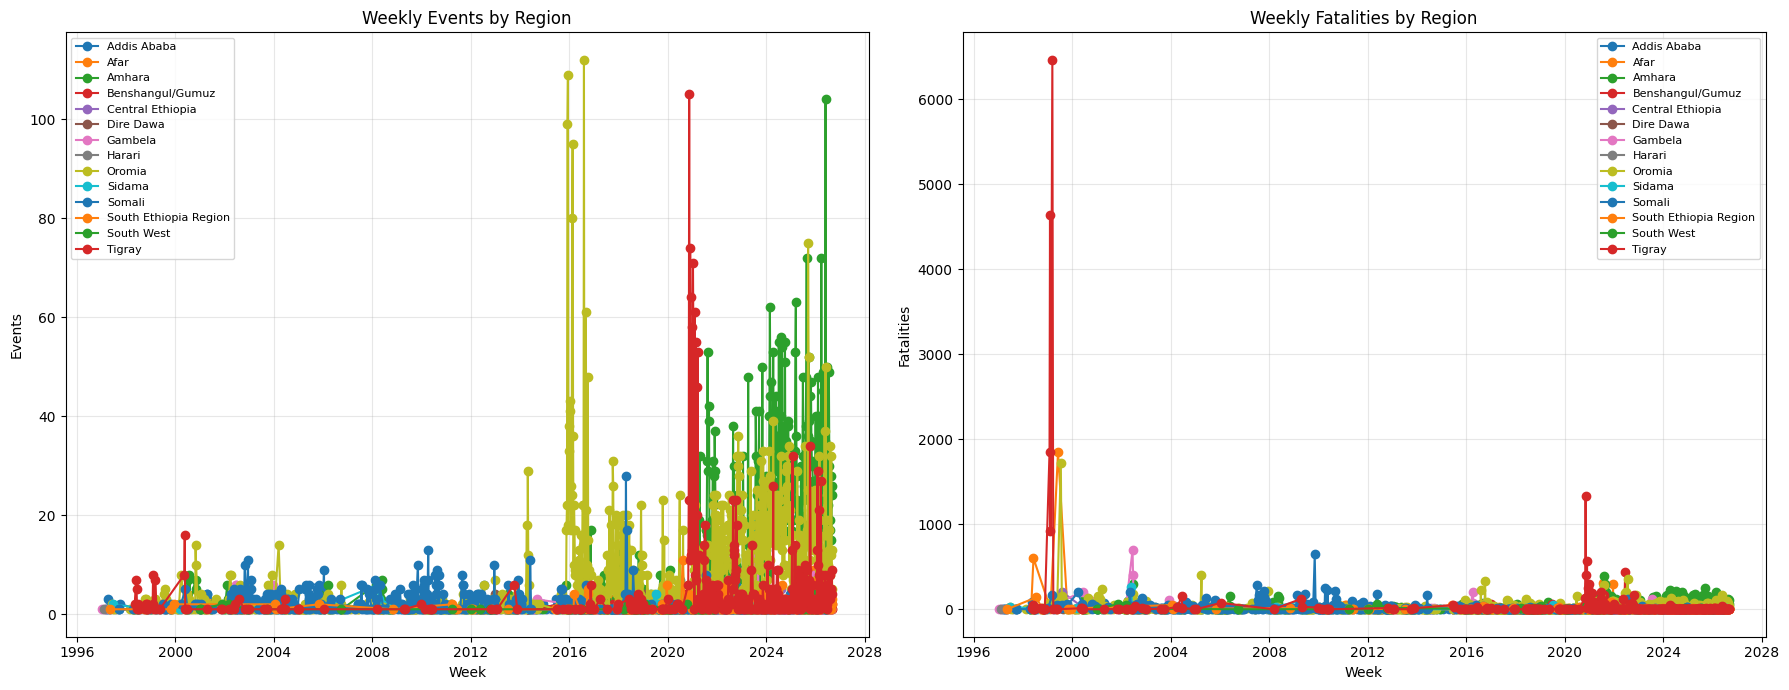

In [133]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for region, group in region_weekly_summary.groupby('ADMIN1'):
    group = group.sort_values('WEEK')
    axes[0].plot(group['WEEK'], group['EVENTS'], marker='o', label=region)
    axes[1].plot(group['WEEK'], group['FATALITIES'], marker='o', label=region)

axes[0].set_title("Weekly Events by Region")
axes[0].set_xlabel("Week"); axes[0].set_ylabel("Events")
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)

axes[1].set_title("Weekly Fatalities by Region")
axes[1].set_xlabel("Week"); axes[1].set_ylabel("Fatalities")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

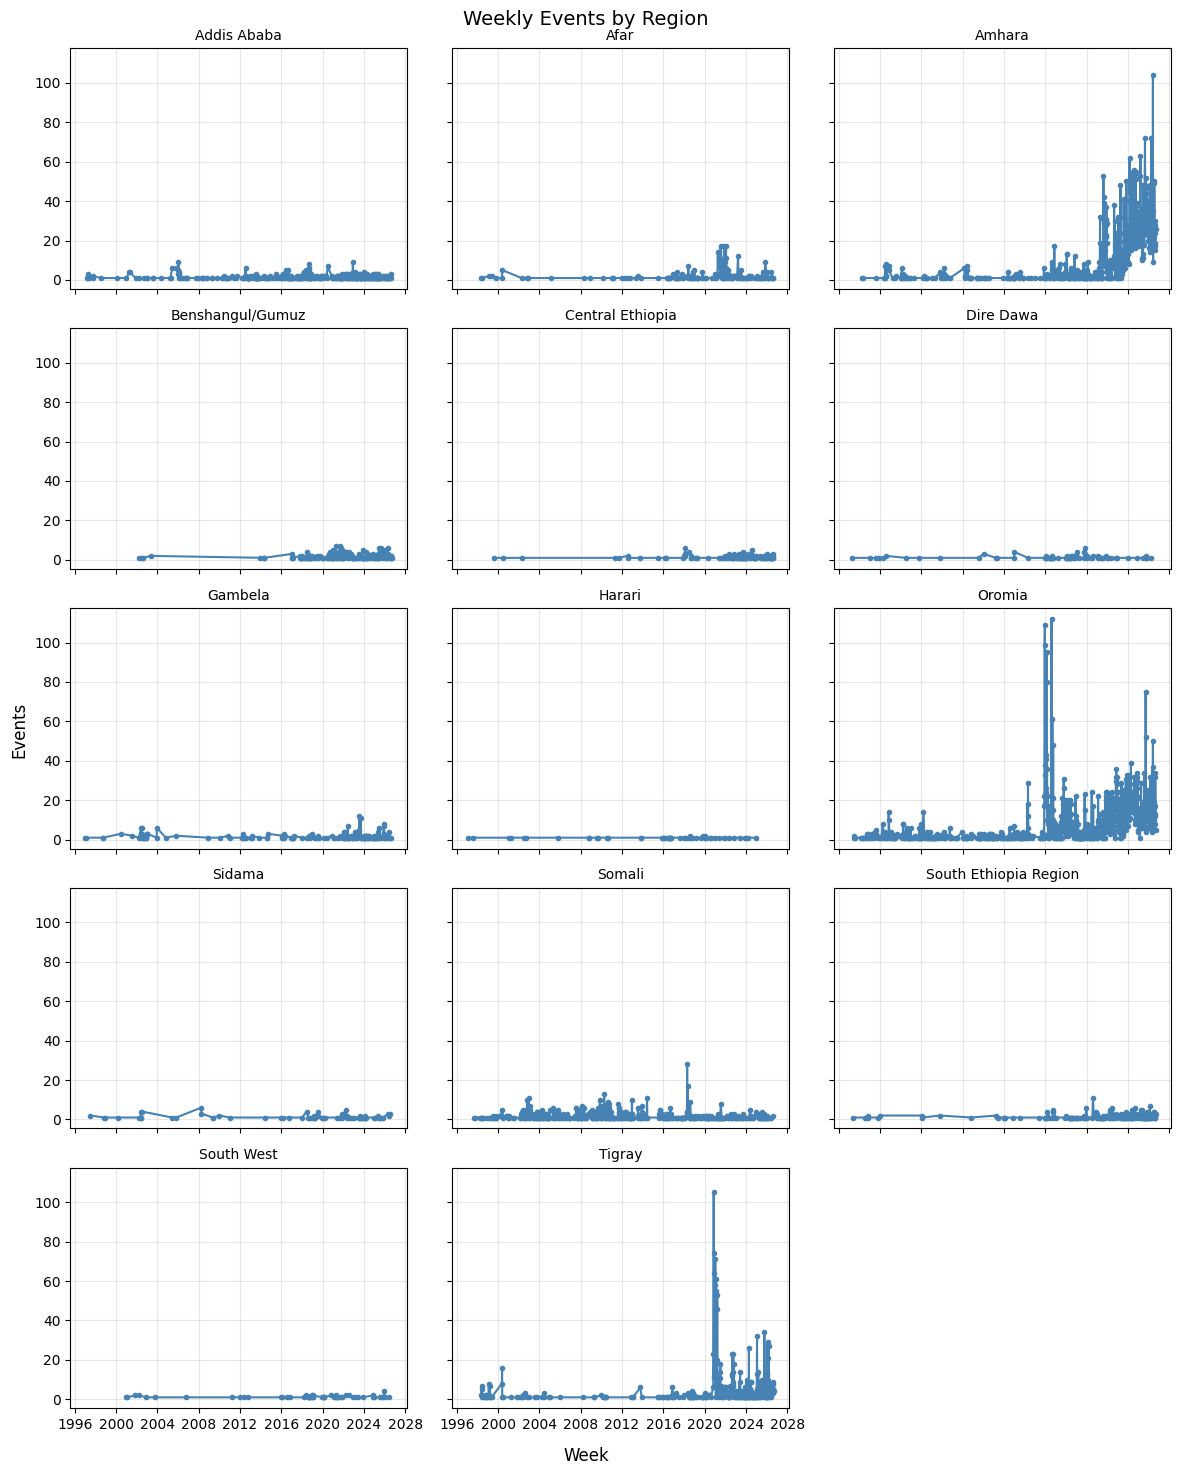

In [134]:
import matplotlib.pyplot as plt

regions = sorted(region_weekly_summary['ADMIN1'].unique())
ncols = 3
nrows = -(-len(regions) // ncols)  # ceil division

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows),
                         sharex=True, sharey=True)
axes = axes.flatten()

for i, region in enumerate(regions):
    g = region_weekly_summary[region_weekly_summary['ADMIN1'] == region].sort_values('WEEK')
    axes[i].plot(g['WEEK'], g['EVENTS'], color='steelblue', marker='.')
    axes[i].set_title(region, fontsize=10)
    axes[i].grid(alpha=0.3)

# Hide unused panels
for j in range(len(regions), len(axes)):
    axes[j].axis('off')

fig.suptitle("Weekly Events by Region", fontsize=14)
fig.supxlabel("Week")
fig.supylabel("Events")
plt.tight_layout()
plt.show()

In [135]:
from IPython.display import HTML, display

weekly_summary = (
    df.groupby(['WEEK'])
    .agg({
        'EVENTS': 'sum',
        'FATALITIES': 'sum'
    })
    .reset_index()
)

display(HTML(
    '<div style="max-height: 200px; overflow: auto;">'
    + weekly_summary.to_html(index=False)
    + '</div>'
))

WEEK,EVENTS,FATALITIES
1997-01-11,1,0
1997-02-08,1,2
1997-02-15,1,0
1997-03-15,1,0
1997-03-29,1,0
1997-04-12,3,1
1997-04-26,1,0
1997-05-03,1,1
1997-05-10,1,0
1997-06-07,2,16


In [136]:
weekly_summary[['EVENTS','FATALITIES']].describe()

,EVENTS,FATALITIES
count,1158.000000,1158.000000
mean,16.693437,74.957686
std,22.550628,272.855040
min,1.000000,0.000000
25%,2.000000,5.000000
50%,6.000000,24.000000
75%,22.750000,85.750000
max,163.000000,6729.000000


In [137]:

weekly_summary[['EVENTS','FATALITIES']].mean()

EVENTS        16.693437
FATALITIES    74.957686
dtype: float64

In [138]:
weekly_summary['FATALITIES-Z'] = (
    (weekly_summary['FATALITIES'] - weekly_summary['FATALITIES'].mean())
    / weekly_summary['FATALITIES'].std()
)

weekly_summary[['FATALITIES','FATALITIES-Z']]

from IPython.display import HTML, display

display(HTML(
    '<div style="max-height: 200px; overflow: auto;">'
    + weekly_summary.to_html(index=False)
    + '</div>'
))

WEEK,EVENTS,FATALITIES,FATALITIES-Z
1997-01-11,1,0,-0.274716
1997-02-08,1,2,-0.267386
1997-02-15,1,0,-0.274716
1997-03-15,1,0,-0.274716
1997-03-29,1,0,-0.274716
1997-04-12,3,1,-0.271051
1997-04-26,1,0,-0.274716
1997-05-03,1,1,-0.271051
1997-05-10,1,0,-0.274716
1997-06-07,2,16,-0.216077


In [139]:
high_fatality_weeks = weekly_summary[weekly_summary['FATALITIES-Z'] > 2]

high_fatality_weeks

,WEEK,EVENTS,FATALITIES,FATALITIES-Z
22,1998-06-06,6,655,2.125826
44,1999-01-30,2,1846,6.490781
45,1999-02-06,8,4631,16.697666
46,1999-02-13,3,926,3.119027
48,1999-03-13,11,6729,24.386730
55,1999-06-05,2,1846,6.490781
57,1999-07-17,4,1720,6.028997
136,2002-06-15,11,1045,3.555156
385,2009-11-07,10,644,2.085511
853,2020-11-07,29,1394,4.834224
